**Import libraries**

In [10]:
import pandas as pd
from sklearn.preprocessing import MinMaxScaler, StandardScaler
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from datetime import date

from sklearn.model_selection import train_test_split
from tensorflow import keras
from tensorflow.keras.layers import *
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import mean_squared_error as mse
from sklearn.metrics import mean_absolute_error as mae

def mape(y_true, y_pred):
    # Convert to numpy arrays if they are not already
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    # Avoid division by zero (for cases where actual value is zero)
    # Replace zeroes in the true values with a small number (e.g., 1e-10)
    y_true = np.where(y_true == 0, 1e-10, y_true)

    # Calculate MAPE
    error = np.abs((y_true - y_pred) / y_true) * 100
    return np.mean(error)

In [11]:
def smape(y_true, y_pred):
    numerator = np.abs(y_pred - y_true)
    denominator = (np.abs(y_pred) + np.abs(y_true)) / 2
    smape_val = np.mean(numerator / np.where(denominator == 0, 1, denominator)) * 100
    return smape_val

## **Data Preprocessing**

Read the data

In [18]:
train_path = "/content/train_data.xlsx"
val_path = "/content/validation_data.xlsx"

df_train = pd.read_excel(train_path)
df_val = pd.read_excel(val_path)

In [19]:
df_train = df_train.set_index('Date') #set index to 'Date'
df_val = df_val.set_index('Date')

In [20]:
df_train

,Power1,Power2,Power3,Power4,Power5,Power6,Power7,Power8,Power9,Power10,...,Power87,Power88,Power89,Power90,Power91,Power92,Power93,Power94,Power95,Power96
Date,,,,,,,,,,,,,,,,,,,,,
2022-01-01,0.5224,0.5170,0.4889,0.5746,0.5187,0.5568,0.5549,0.5355,0.4970,0.5217,...,0.3769,0.2992,0.2558,0.2398,0.1990,0.2282,0.1994,0.1712,0.2339,0.2276
2022-01-02,0.2034,0.1866,0.1830,0.2593,0.1914,0.2003,0.1784,0.2068,0.1970,0.2086,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2022-01-03,0.5357,0.5203,0.5221,0.5079,0.4401,0.2406,0.2237,0.2676,0.2461,0.2354,...,0.6881,0.5308,0.5401,0.5214,0.4476,0.4937,0.5255,0.4434,0.5276,0.4628
2022-01-04,0.5291,0.5344,0.4819,0.5357,0.5445,0.4390,0.4513,0.4587,0.4465,0.5004,...,0.7621,0.7077,0.7638,0.7399,0.7962,0.6121,0.6241,0.5703,0.5478,0.5497
2022-01-05,0.6456,0.5800,0.5472,0.5141,0.5761,0.5942,0.4822,0.6394,0.5833,0.5641,...,0.7449,0.5639,0.6878,0.5845,0.6220,0.5959,0.5147,0.5854,0.6962,0.5521
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2023-12-27,0.2156,0.2637,0.2404,0.2773,0.2333,0.2390,0.2137,0.1767,0.1833,0.1777,...,0.5842,0.3539,0.3440,0.3005,0.2531,0.2456,0.2255,0.1922,0.2292,0.1772
2023-12-28,0.1967,0.2254,0.1874,0.1377,0.1321,0.1317,0.1592,0.1468,0.1282,0.2522,...,0.3560,0.3949,0.3305,0.3171,0.4024,0.3468,0.3891,0.3009,0.3275,0.2876
2023-12-29,0.2630,0.2720,0.2925,0.2769,0.2715,0.2563,0.2841,0.2936,0.2240,0.2006,...,0.4447,0.3628,0.3809,0.3056,0.3187,0.3282,0.2865,0.2672,0.2149,0.2454


In [21]:
df_val

,Power1,Power2,Power3,Power4,Power5,Power6,Power7,Power8,Power9,Power10,...,Power87,Power88,Power89,Power90,Power91,Power92,Power93,Power94,Power95,Power96
Date,,,,,,,,,,,,,,,,,,,,,
2024-01-01,0.1367,0.2140,0.1263,0.1227,0.1743,0.1312,0.1353,0.1395,0.1175,0.1396,...,0.2897,0.3325,0.3057,0.2473,0.3175,0.2701,0.2503,0.2078,0.2603,0.2276
2024-01-02,0.2341,0.2571,0.2059,0.2101,0.1631,0.1586,0.1964,0.1110,0.1198,0.1126,...,0.3995,0.3513,0.2595,0.2523,0.2872,0.2188,0.2149,0.2631,0.2682,0.2238
2024-01-03,0.2647,0.2211,0.2125,0.1769,0.2504,0.1696,0.1849,0.2080,0.1582,0.2010,...,0.3750,0.3170,0.3078,0.3580,0.3578,0.3276,0.2657,0.2796,0.2755,0.2537
2024-01-04,0.2119,0.2464,0.1926,0.2608,0.2288,0.2367,0.2390,0.2126,0.1838,0.1921,...,0.4050,0.4143,0.3827,0.5039,0.3887,0.2955,0.1881,0.2375,0.2162,0.2513
2024-01-05,0.2269,0.2499,0.2341,0.1996,0.1912,0.2441,0.1888,0.2068,0.2069,0.1874,...,0.4259,0.3397,0.3220,0.3594,0.2769,0.2379,0.2417,0.2228,0.1968,0.1807
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-05-27,0.6865,0.7218,0.7595,0.6752,0.6290,0.6572,0.7032,0.6269,0.5777,0.6673,...,0.7623,0.7555,0.7331,0.6917,0.7105,0.6695,0.6039,0.6270,0.7371,0.6136
2024-05-28,0.7199,0.6409,0.6860,0.6655,0.6437,0.6298,0.7375,0.6747,0.5395,0.6385,...,0.8602,0.8425,0.9208,0.8956,0.8569,0.8083,0.8491,0.8119,0.8071,0.7057
2024-05-29,0.7321,0.7834,0.8466,0.7558,0.6692,0.6762,0.7124,0.7239,0.7340,0.6238,...,0.8273,0.7975,0.7493,0.8291,0.9259,0.7454,0.7873,0.7592,0.7605,0.6160


Function to categorize into different time frames

In [22]:
#time series features
def create_time_series_features(df, date_col='timestamp'):
    """
    Creates time series features based on a datetime column (not index).

    Parameters:
        df (pd.DataFrame): The input DataFrame.
        date_col (str): The name of the datetime column.

    Returns:
        pd.DataFrame: DataFrame with additional time-based features.
    """
    df = df.copy()

    # Ensure it's datetime
    df[date_col] = pd.to_datetime(df[date_col])

    df['hour'] = df[date_col].dt.hour
    df['month'] = df[date_col].dt.month
    df['year'] = df[date_col].dt.year
    df['dayofweek'] = df[date_col].dt.dayofweek #starts on monday
    df['dayofyear'] = df[date_col].dt.dayofyear
    df['quarter'] = df[date_col].dt.quarter
    df['dayofmonth'] = df[date_col].dt.day
    df['weekofyear'] = df[date_col].dt.isocalendar().week
    df['date_offset'] = (df[date_col].dt.month * 100 + df[date_col].dt.day - 320) % 1300
    df['season'] = pd.cut(df['date_offset'], [-1, 300, 602, 900, 1301],
                          labels=[0, 1,2,3])
    #since we observe periodic patterns for time of day and month of year, we add new features
    df['hour_sin'] = np.sin(2 * np.pi * df['hour'] / 24)
    df['hour_cos'] = np.cos(2 * np.pi * df['hour'] / 24)

    df['month_sin'] = np.sin(2 * np.pi * df['month'] / 12)
    df['month_cos'] = np.cos(2 * np.pi * df['month'] / 12)

    df['week_sin'] = np.sin(2 * np.pi * df['dayofweek'] / 7)
    df['week_cos'] = np.cos(2 * np.pi * df['dayofweek'] / 7)

    return df


In [23]:
def add_holidays_train(df):
    # Define holiday dates (2022)
    holiday_dates = [
        date(2022, 1, 1), date(2022, 1, 2), date(2022, 1, 3),
        date(2022, 1, 31), date(2022, 2, 1), date(2022, 2, 2), date(2022, 2, 3),
        date(2022, 2, 4), date(2022, 2, 5), date(2022, 2, 6),
        date(2022, 4, 3), date(2022, 4, 4), date(2022, 4, 5),
        date(2022, 4, 30), date(2022, 5, 1), date(2022, 5, 2), date(2022, 5, 3), date(2022, 5, 4),
        date(2022, 6, 3), date(2022, 6, 4), date(2022, 6, 5),
        date(2022, 9, 10), date(2022, 9, 11), date(2022, 9, 12),
        date(2022, 10, 1), date(2022, 10, 2), date(2022, 10, 3), date(2022, 10, 4),
        date(2022, 10, 5), date(2022, 10, 6), date(2022, 10, 7),
        date(2023, 1, 1), date(2023, 1, 2),
        date(2023, 1, 21),date(2023, 1, 22),date(2023, 1, 23),date(2023, 1, 24),date(2023, 1, 25),
        date(2023, 1, 26),date(2023, 1, 27),date(2023, 4,5),date(2023, 4,29),date(2023, 4, 30),
        date(2023, 5, 1),date(2023, 5, 2),date(2023, 5, 3),date(2023, 6, 22), date(2023, 6, 23), date(2023, 6, 24),
        date(2023, 9, 29),date(2023, 9, 30),date(2023, 10, 1),
        date(2023, 10, 2),date(2023, 10, 3),date(2023, 10, 4),date(2023, 10, 5),date(2023, 10, 6)
    ]

    # Create holiday column: 1 if the date is a holiday, else 0
    df['National Holiday'] = pd.Index(df.index.date).isin(holiday_dates).astype(int)

    return df

def add_holidays_val(df):
  # Define holiday dates (2024)
  holiday_dates = [
      date(2024,1,1), date(2024,2,10),date(2024,2,11),date(2024,2,12),date(2024,2,13),
      date(2024,2,14),date(2024,2,15),date(2024,2,16),date(2024,2,17),
      date(2024,4,4),date(2024,4,5),date(2024,4,6),
      date(2024,5,1), date(2024,5,2), date(2024,5,3), date(2024,5,4), date(2024,5,5),
    ]

    #date(2024,9,15), date(2024,9,16), date(2024,9,17),
    #date(2024,10,1), date(2024,10,2), date(2024,10,3), date(2024,10,4), date(2024,10,5),
    #date(2024,10,6), date(2024,10,7),

  # Create holiday column: 1 if the date is a holiday, else 0
  df['National Holiday'] = pd.Index(df.index.date).isin(holiday_dates).astype(int)

  return df

In [24]:
!pip install openmeteo-requests
!pip install requests-cache retry-requests numpy pandas

In [25]:
import openmeteo_requests

import pandas as pd
import requests_cache
from retry_requests import retry

# Setup the Open-Meteo API client with cache and retry on error
cache_session = requests_cache.CachedSession('.cache', expire_after = -1)
retry_session = retry(cache_session, retries = 5, backoff_factor = 0.2)
openmeteo = openmeteo_requests.Client(session = retry_session)

# Make sure all required weather variables are listed here
# The order of variables in hourly or daily is important to assign them correctly below
url = "https://archive-api.open-meteo.com/v1/archive"
params = {
	"latitude": 30.536,
	"longitude": 120.686,
	"start_date": "2022-01-01",
	"end_date": "2024-06-01",
	"daily": ["sunrise", "sunset", "temperature_2m_mean", "sunshine_duration", "precipitation_sum", "shortwave_radiation_sum", "weather_code", "dew_point_2m_mean"],
	"hourly": ["relative_humidity_2m", "temperature_2m", "apparent_temperature", "cloud_cover", "wind_speed_10m", "is_day", "dew_point_2m"],
	"timezone": "Asia/Shanghai"
}
responses = openmeteo.weather_api(url, params=params)

# Process first location. Add a for-loop for multiple locations or weather models
response = responses[0]
print(f"Coordinates {response.Latitude()}°N {response.Longitude()}°E")
print(f"Elevation {response.Elevation()} m asl")
print(f"Timezone {response.Timezone()}{response.TimezoneAbbreviation()}")
print(f"Timezone difference to GMT+0 {response.UtcOffsetSeconds()} s")

# Process hourly data. The order of variables needs to be the same as requested.
hourly = response.Hourly()
hourly_relative_humidity_2m = hourly.Variables(0).ValuesAsNumpy()
hourly_temperature_2m = hourly.Variables(1).ValuesAsNumpy()
hourly_apparent_temperature = hourly.Variables(2).ValuesAsNumpy()
hourly_cloud_cover = hourly.Variables(3).ValuesAsNumpy()
hourly_wind_speed_10m = hourly.Variables(4).ValuesAsNumpy()
hourly_is_day = hourly.Variables(5).ValuesAsNumpy()
hourly_dew_point_2m = hourly.Variables(6).ValuesAsNumpy()

hourly_data = {"date": pd.date_range(
	start = pd.to_datetime(hourly.Time(), unit = "s", utc = True),
	end = pd.to_datetime(hourly.TimeEnd(), unit = "s", utc = True),
	freq = pd.Timedelta(seconds = hourly.Interval()),
	inclusive = "left"
)}

hourly_data["relative_humidity_2m"] = hourly_relative_humidity_2m
hourly_data["temperature_2m"] = hourly_temperature_2m
hourly_data["apparent_temperature"] = hourly_apparent_temperature
hourly_data["cloud_cover"] = hourly_cloud_cover
hourly_data["wind_speed_10m"] = hourly_wind_speed_10m
hourly_data["is_day"] = hourly_is_day
hourly_data["dew_point_2m"] = hourly_dew_point_2m

hourly_dataframe = pd.DataFrame(data = hourly_data)

# Process daily data. The order of variables needs to be the same as requested.
daily = response.Daily()
daily_sunrise = daily.Variables(0).ValuesInt64AsNumpy()
daily_sunset = daily.Variables(1).ValuesInt64AsNumpy()
daily_temperature_2m_mean = daily.Variables(2).ValuesAsNumpy()
daily_sunshine_duration = daily.Variables(3).ValuesAsNumpy()
daily_precipitation_sum = daily.Variables(4).ValuesAsNumpy()
daily_shortwave_radiation_sum = daily.Variables(5).ValuesAsNumpy()
daily_weather_code = daily.Variables(6).ValuesAsNumpy()
daily_dew_point_2m_mean = daily.Variables(7).ValuesAsNumpy()

daily_data = {"date": pd.date_range(
	start = pd.to_datetime(daily.Time(), unit = "s", utc = True),
	end = pd.to_datetime(daily.TimeEnd(), unit = "s", utc = True),
	freq = pd.Timedelta(seconds = daily.Interval()),
	inclusive = "left"
)}

daily_data["sunrise"] = daily_sunrise
daily_data["sunset"] = daily_sunset
daily_data["temperature_2m_mean"] = daily_temperature_2m_mean
daily_data["sunshine_duration"] = daily_sunshine_duration
daily_data["precipitation_sum"] = daily_precipitation_sum
daily_data["shortwave_radiation_sum"] = daily_shortwave_radiation_sum
daily_data["weather_code"] = daily_weather_code
daily_data["dew_point_2m_mean"] = daily_dew_point_2m_mean

daily_dataframe = pd.DataFrame(data = daily_data)


Coordinates 30.544815063476562°N 120.70588684082031°E
Elevation 6.0 m asl
Timezone b'Asia/Shanghai'b'GMT+8'
Timezone difference to GMT+0 28800 s


In [26]:
hourly_weather_train = hourly_dataframe[8:17528]
hourly_weather_val = hourly_dataframe[17529:21176]

In [27]:
daily_weather_train = daily_dataframe[8:731]
daily_weather_val = daily_dataframe[732:1457]

Create a new melted Dataframe having indexof timestamps of 15-min-interval

In [28]:
df_train.columns = pd.date_range(start='00:00', periods=96, freq='15min').time #transform column index to time
df_reset = df_train.reset_index() #before melting gotta reset index
df_long = df_reset.melt(id_vars='Date', var_name= 'Time', value_name='Power Usage')
df_long['timestamp'] = pd.to_datetime(df_long['Date'].astype(str) + ' ' + df_long['Time'].astype(str))
df_long = create_time_series_features(df_long)
df_long= df_long.set_index('timestamp')
df_long.sort_index(inplace=True)
df_long = add_holidays_train(df_long)
df_long = df_long.drop(columns = ['Date','Time'])

#handling missing values using interpolate
df_filled = df_long.copy()
df_filled['Power Usage'] = df_filled['Power Usage'].interpolate(method='linear')
df_filled.head()

,Power Usage,hour,month,year,dayofweek,dayofyear,quarter,dayofmonth,weekofyear,date_offset,season,hour_sin,hour_cos,month_sin,month_cos,week_sin,week_cos,National Holiday
timestamp,,,,,,,,,,,,,,,,,,
2022-01-01 00:00:00,0.5224,0,1,2022,5,1,1,1,52,1081,3,0.000000,1.000000,0.5,0.866025,-0.974928,-0.222521,1
2022-01-01 00:15:00,0.5170,0,1,2022,5,1,1,1,52,1081,3,0.000000,1.000000,0.5,0.866025,-0.974928,-0.222521,1
2022-01-01 00:30:00,0.4889,0,1,2022,5,1,1,1,52,1081,3,0.000000,1.000000,0.5,0.866025,-0.974928,-0.222521,1
2022-01-01 00:45:00,0.5746,0,1,2022,5,1,1,1,52,1081,3,0.000000,1.000000,0.5,0.866025,-0.974928,-0.222521,1
2022-01-01 01:00:00,0.5187,1,1,2022,5,1,1,1,52,1081,3,0.258819,0.965926,0.5,0.866025,-0.974928,-0.222521,1


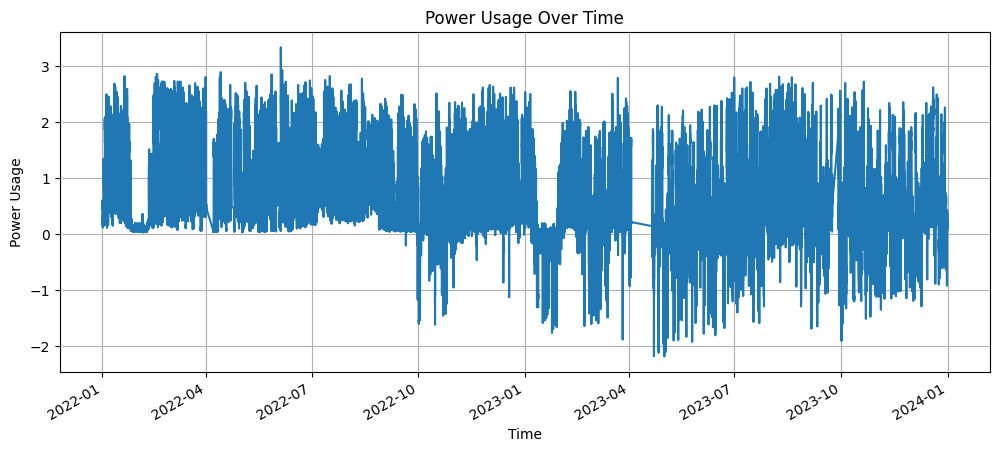

In [29]:
import matplotlib.pyplot as plt

df_filled['Power Usage'].plot(figsize=(12, 5), title='Power Usage Over Time')
plt.xlabel('Time')
plt.ylabel('Power Usage')
plt.grid(True)
plt.show()

In [30]:
df_val.columns = pd.date_range(start='00:00', periods=96, freq='15min').time #transform column index to time
df_reset_val = df_val.reset_index() #before melting gotta reset index
df_val_long = df_reset_val.melt(id_vars='Date', var_name= 'Time', value_name='Power Usage')
df_val_long['timestamp'] = pd.to_datetime(df_val_long['Date'].astype(str) + ' ' + df_val_long['Time'].astype(str))
df_val_long = create_time_series_features(df_val_long)
df_val_long= df_val_long.set_index('timestamp')
df_val_long.sort_index(inplace=True)
df_val_long = add_holidays_val(df_val_long)
df_val_long = df_val_long.drop(columns = ['Date','Time'])

#handling missing values using interpolate
df_val_filled = df_val_long.copy()
df_val_filled['Power Usage'] = df_val_filled['Power Usage'].interpolate(method='linear')

df_val_filled.head()

,Power Usage,hour,month,year,dayofweek,dayofyear,quarter,dayofmonth,weekofyear,date_offset,season,hour_sin,hour_cos,month_sin,month_cos,week_sin,week_cos,National Holiday
timestamp,,,,,,,,,,,,,,,,,,
2024-01-01 00:00:00,0.1367,0,1,2024,0,1,1,1,1,1081,3,0.000000,1.000000,0.5,0.866025,0.0,1.0,1
2024-01-01 00:15:00,0.2140,0,1,2024,0,1,1,1,1,1081,3,0.000000,1.000000,0.5,0.866025,0.0,1.0,1
2024-01-01 00:30:00,0.1263,0,1,2024,0,1,1,1,1,1081,3,0.000000,1.000000,0.5,0.866025,0.0,1.0,1
2024-01-01 00:45:00,0.1227,0,1,2024,0,1,1,1,1,1081,3,0.000000,1.000000,0.5,0.866025,0.0,1.0,1
2024-01-01 01:00:00,0.1743,1,1,2024,0,1,1,1,1,1081,3,0.258819,0.965926,0.5,0.866025,0.0,1.0,1


# **LSTM MODEL**
From dataframe to Numpy Array


*   Input data needs to be split into X and y
*   X is a 2D np.array (# of records, # of input sequence)
*   y is a 2D np.array (# of records)
*  n_input/ window size is the number for historical imports to be used in forecasting




## Creating Input Data For LSTM

In [31]:
hourly_weather_train

,date,relative_humidity_2m,temperature_2m,apparent_temperature,cloud_cover,wind_speed_10m,is_day,dew_point_2m
8,2022-01-01 00:00:00+00:00,85.303146,4.324,1.478300,99.0,7.289444,1.0,2.074
9,2022-01-01 01:00:00+00:00,77.219894,6.424,3.864357,100.0,6.130579,1.0,2.724
10,2022-01-01 02:00:00+00:00,73.831680,6.974,4.547731,100.0,5.091168,1.0,2.624
11,2022-01-01 03:00:00+00:00,70.593506,7.474,4.973802,100.0,5.411986,1.0,2.474
12,2022-01-01 04:00:00+00:00,66.325294,8.024,5.663666,100.0,4.024922,1.0,2.124
...,...,...,...,...,...,...,...,...
17523,2023-12-31 19:00:00+00:00,90.681061,0.774,-2.344664,78.0,6.214563,0.0,-0.576
17524,2023-12-31 20:00:00+00:00,90.684715,0.824,-2.222564,84.0,5.771239,0.0,-0.526
17525,2023-12-31 21:00:00+00:00,91.340538,0.724,-2.479831,100.0,6.849467,0.0,-0.526
17526,2023-12-31 22:00:00+00:00,89.388733,1.024,-2.337068,82.0,7.928178,0.0,-0.526


Create Train Test Split

In [32]:
# Convert to datetime, remove timezone, and strip time info
hourly_weather_train['date'] = pd.to_datetime(hourly_weather_train['date']).dt.tz_localize(None).dt.date
# Set as index
hourly_weather_train.set_index('date', inplace=True)

<ipython-input-32-520607aeeb3f>:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  hourly_weather_train['date'] = pd.to_datetime(hourly_weather_train['date']).dt.tz_localize(None).dt.date


In [33]:
# Convert to datetime, remove timezone, and strip time info
hourly_weather_val['date'] = pd.to_datetime(hourly_weather_val['date']).dt.tz_localize(None).dt.date
# Set as index
hourly_weather_val.set_index('date', inplace=True)

<ipython-input-33-0faea42ebcc6>:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  hourly_weather_val['date'] = pd.to_datetime(hourly_weather_val['date']).dt.tz_localize(None).dt.date


In [34]:
df_train =  pd.merge(df_filled,hourly_weather_train, left_index=True,right_index=True,how = 'left')
df_train = df_train.ffill().bfill()

In [35]:
df_val =  pd.merge(df_val_filled, hourly_weather_val, left_index=True,right_index=True,how = 'left')
df_val = df_val.ffill().bfill()

In [36]:
df_train.columns

Index(['Power Usage', 'hour', 'month', 'year', 'dayofweek', 'dayofyear',
       'quarter', 'dayofmonth', 'weekofyear', 'date_offset', 'season',
       'hour_sin', 'hour_cos', 'month_sin', 'month_cos', 'week_sin',
       'week_cos', 'National Holiday', 'relative_humidity_2m',
       'temperature_2m', 'apparent_temperature', 'cloud_cover',
       'wind_speed_10m', 'is_day', 'dew_point_2m'],
      dtype='object')

In [51]:
df_model_train = df_train[['Power Usage','season','month','hour','year','week_sin','week_cos','National Holiday','apparent_temperature']].copy()
df_model_test = df_val[['Power Usage','season', 'month','hour','year','week_sin','week_cos','National Holiday','apparent_temperature']].copy()

# Downsample to hourly frequency using the mean
#df_model2 = df_model2.resample('h').mean() #resample produce Nans
#df_model2 = df_model2.interpolate(method='linear')  # Linear interpolation

In [52]:
# ---- Normalization (train/test split must be done before this) ----
#features_to_scale = ['temperature_2m_mean']  # Example feature

# Create two separate scalers
#feature_scaler = MinMaxScaler()

# Fit only on training data
#df_model_train[features_to_scale] = feature_scaler.fit_transform(df_model_train[features_to_scale])
#df_model_test[features_to_scale] = feature_scaler.transform(df_model_test[features_to_scale])

In [53]:
#data normalization, MinMax is better for LSTM
target_scaler = MinMaxScaler() #StandardScaler()
df_model_train['Power Usage'] = target_scaler.fit_transform(df_model_train['Power Usage'].values.reshape(-1,1))
df_model_test['Power Usage'] = target_scaler.transform(df_model_test['Power Usage'].values.reshape(-1,1))
#1d->2d: reshape number of rows to auto fit all data, 1 should be one col

In [54]:
# [[[power supplt, sin], [power, sin], [power sin], [power,sin], [power,sin]]] ->  [power]
# [[[2], [3], [4], [5], [6]]] [7]
# [[[3], [4], [5], [6], [7]]] [8]

def create_sequences(df, target_column, window_size=4):
    df_as_np = df.to_numpy()
    X = []
    y = []
    for i in range(len(df_as_np) - window_size):
        row = df_as_np[i : i + window_size]
        X.append(row)
        label = df_as_np[i + window_size, df.columns.get_loc(target_column)]  # Get target column index
        y.append(label)
    return np.array(X), np.array(y)

In [55]:
window_size = 4 #5 hours prev value
X_train, y_train = create_sequences(df_model_train, 'Power Usage', window_size)
X_test, y_test = create_sequences(df_model_test, 'Power Usage', window_size)

X_train, X_val, y_train, y_val = train_test_split(X_train,y_train,test_size=0.2, random_state = 42)

X_train.shape, y_train.shape, X_val.shape, y_val.shape, X_test.shape, y_test.shape

((67017, 4, 9), (67017,), (16755, 4, 9), (16755,), (18083, 4, 9), (18083,))

## Building the LSTM Model



*   first LSTM layer learns hourly, daily patterns.
*   Dropout layer is added to prevent overfitting
*   second LSTM layer learns weekly, monthly patterns.
*   too much LSTM layers might caught overfitting and analysing noises.  



In [56]:
#Building the LSTM model
n_input = X_train.shape[1] #window size
n_features = X_train.shape[2] #number of features

model2 = keras.Sequential()
model2.add(LSTM(units=100, return_sequences = True, input_shape = (n_input, n_features)))
model2.add(Dropout(0.3)) #dropout layer manages overfitting
model2.add(LSTM(units=64, return_sequences= True))
model2.add(Dropout(0.3)) #dropout layer manages overfitting
model2.add(LSTM(units=50, return_sequences= False))
model2.add(Dropout(0.3)) #dropout layer manages overfitting
model2.add(Dense(8, activation = 'relu'))
model2.add(Dense(1, activation = 'linear'))

model2.summary()

/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_3 (LSTM)                   │ (None, 4, 100)         │        44,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 4, 100)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_4 (LSTM)                   │ (None, 4, 64)          │        42,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 4, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_5 (LSTM)                   │ (None, 50)             │        23,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 8)              │           408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,657 (428.35 KB)

 Trainable params: 109,657 (428.35 KB)

 Non-trainable params: 0 (0.00 B)

In [57]:
#early stopping condition to prevent overfitting, val_loss starts to increase while training loss continues to decrease
early_stopping = EarlyStopping(monitor = 'val_loss',
                               patience = 2,
                               restore_best_weights = True ) # patience is number of epochs it will continue even if it didn't improve

In [58]:
model2.compile(optimizer=Adam(learning_rate=1e-4) ,
              loss = 'mean_squared_error',
              metrics = ['RootMeanSquaredError'])

In [59]:
model2.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=100, callbacks=early_stopping)

Epoch 1/100
2095/2095 ━━━━━━━━━━━━━━━━━━━━ 41s 16ms/step - RootMeanSquaredError: 0.1856 - loss: 0.0375 - val_RootMeanSquaredError: 0.1207 - val_loss: 0.0146
Epoch 2/100
2095/2095 ━━━━━━━━━━━━━━━━━━━━ 38s 15ms/step - RootMeanSquaredError: 0.1316 - loss: 0.0173 - val_RootMeanSquaredError: 0.1190 - val_loss: 0.0142
Epoch 3/100
2095/2095 ━━━━━━━━━━━━━━━━━━━━ 41s 15ms/step - RootMeanSquaredError: 0.1257 - loss: 0.0158 - val_RootMeanSquaredError: 0.1174 - val_loss: 0.0138
Epoch 4/100
2095/2095 ━━━━━━━━━━━━━━━━━━━━ 31s 15ms/step - RootMeanSquaredError: 0.1226 - loss: 0.0150 - val_RootMeanSquaredError: 0.1168 - val_loss: 0.0136
Epoch 5/100
2095/2095 ━━━━━━━━━━━━━━━━━━━━ 32s 15ms/step - RootMeanSquaredError: 0.1192 - loss: 0.0142 - val_RootMeanSquaredError: 0.1130 - val_loss: 0.0128
Epoch 6/100
2095/2095 ━━━━━━━━━━━━━━━━━━━━ 40s 15ms/step - RootMeanSquaredError: 0.1170 - loss: 0.0137 - val_RootMeanSquaredError: 0.1084 - val_loss: 0.0118
Epoch 7/100
2095/2095 ━━━━━━━━━━━━━━━━━━━━ 46s 17ms/step -

<Axes: >

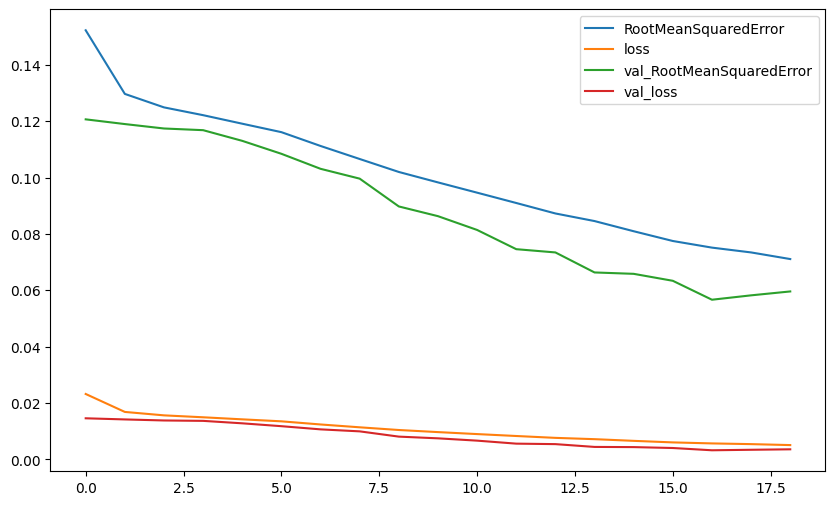

In [60]:
losses_df = pd.DataFrame(model2.history.history)
losses_df.plot(figsize = (10,6))

## Prediction

In [61]:
#save model
from tensorflow.keras.models import save_model,load_model
save_model(model2,'lstm_model_multivariate_week_trig.keras')
lstm_model = load_model('/content/lstm_model_multivariate_week_trig.keras')

Save and Reuse Model

In [62]:
def plot_predictions(model, X, y_scaled, scaler, start=0, end=1000):
    predictions = model.predict(X)

    # Ensure predictions and y are 2D for inverse_transform
    if predictions.ndim == 1:
        predictions = predictions.reshape(-1, 1)
    if y_scaled.ndim == 1:
        y_scaled = y_scaled.reshape(-1, 1)

    # Inverse transform
    predictions_actual = target_scaler.inverse_transform(predictions).flatten()
    y_actual = target_scaler.inverse_transform(y_scaled).flatten()

    # Now they're both 1D
    df = pd.DataFrame(data={
        'date': df_model_test.index,
        'Predictions': predictions_actual,
        'Actuals': y_actual
    })

    # Plot
    plt.plot(df['Actuals'][start:end], label='Actuals')
    plt.plot(df['Predictions'][start:end], label='Predictions',color='r',linestyle ='--')
    plt.title("Plots of actual value vs predictions")
    plt.legend()
    plt.show()

    # Evaluation
    rmse = np.sqrt(mse(y_actual, predictions_actual))
    mae_value = mae(y_actual, predictions_actual)
    mape_value = smape(y_actual, predictions_actual)

    print(f"The root mean square error (RMSE) is: {rmse:.2f}")
    print(f"The mean absolute error (MAE) is: {mae_value:.2f}")
    print(f"The mean absolute percentage error (sMAPE) is: {mape_value:.2f}%")

    return df, rmse, mae_value, mape_value

In [63]:
X_test.shape

(18083, 4, 9)

566/566 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step


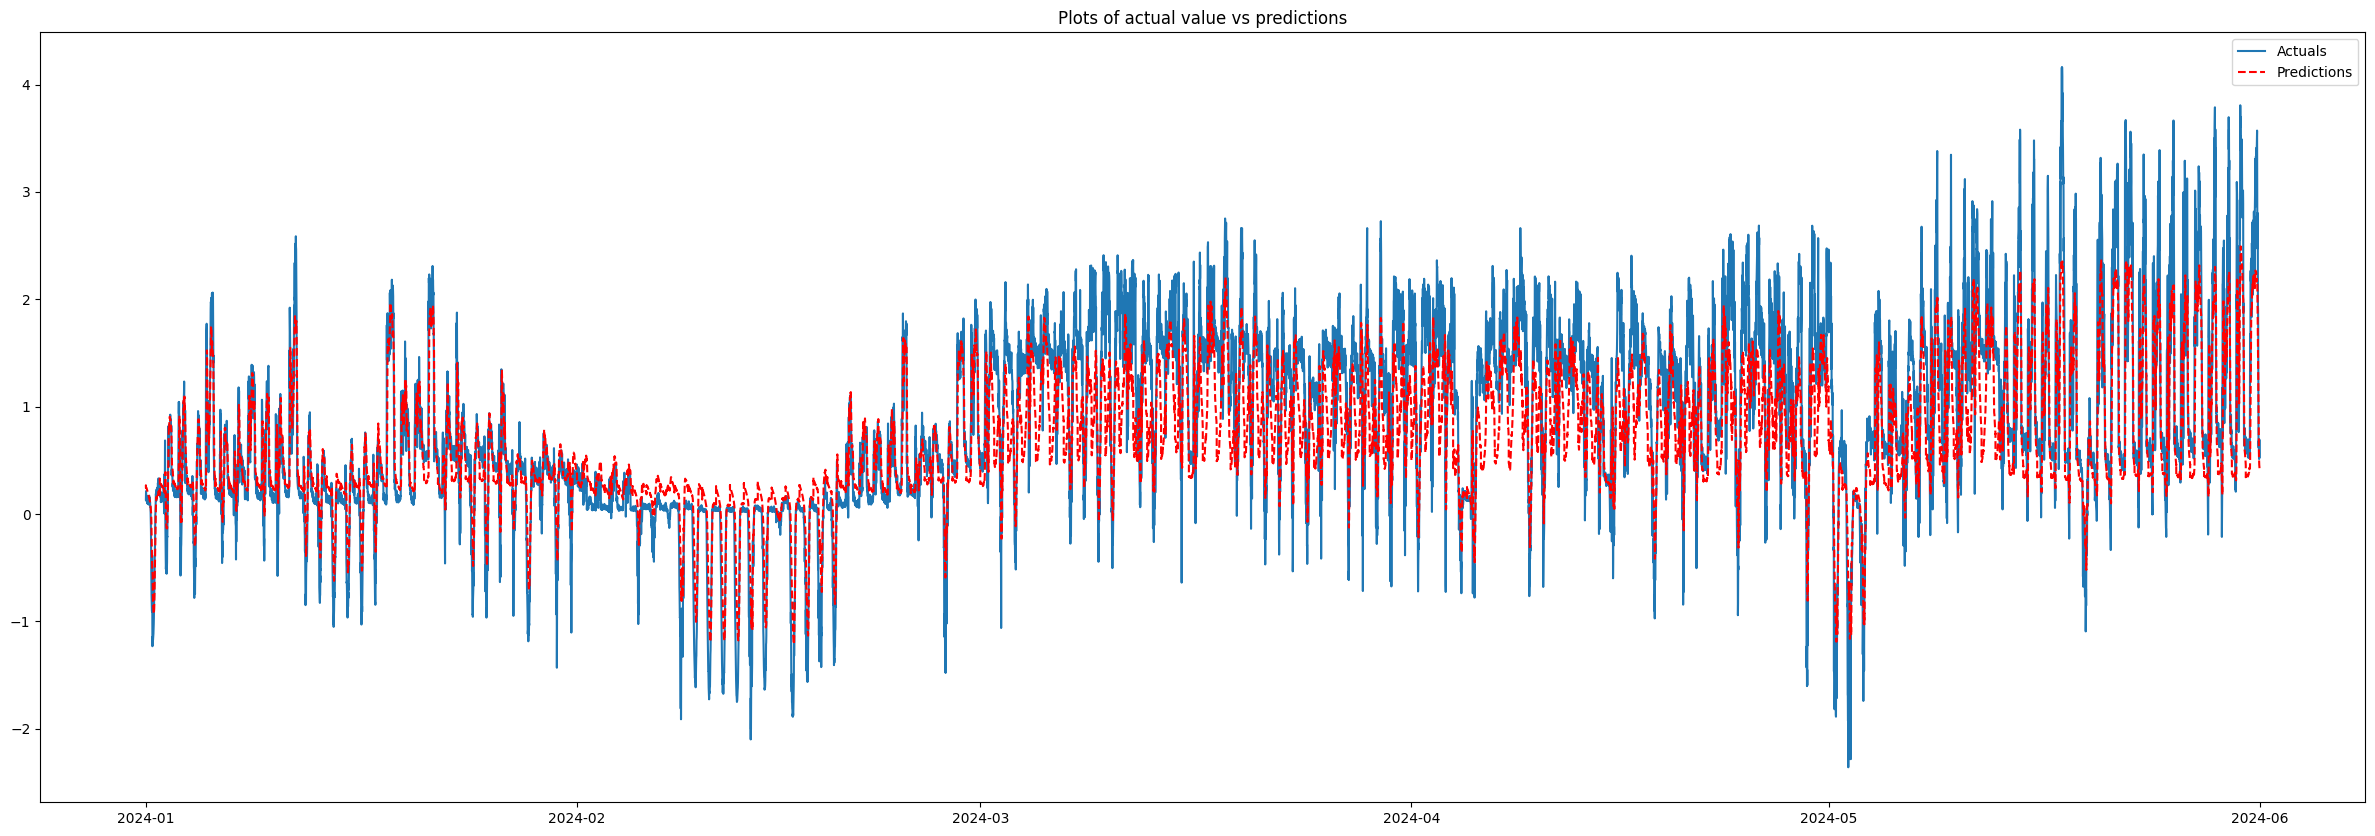

The root mean square error (RMSE) is: 0.54
The mean absolute error (MAE) is: 0.39
The mean absolute percentage error (sMAPE) is: 58.77%


In [64]:
#inverse scaling
predictions = model2.predict(X_test)
predictions_rescaled = target_scaler.inverse_transform(predictions).flatten()

y_test_rescaled = target_scaler.inverse_transform(y_test.reshape(-1,1))
y_test_rescaled = y_test_rescaled.flatten() # Now y_test contains actual values

# Keep only timestamps that correspond to predictions
# Drop the first `window_size` timestamps because they were used for input
timestamps = df_model_test.index[window_size:].to_list()

# Create result DataFrame with timestamps
df = pd.DataFrame({
    'timestamp': timestamps,
    'predictions': predictions_rescaled,
    'actual': y_test_rescaled
})

df['date'] = pd.to_datetime(df['timestamp']).dt.date
df.set_index('timestamp', inplace=True)

plt.figure(figsize=(30, 10))  # Set the size of the figure here
plt.plot(df['actual'], label='Actuals')
plt.plot(df['predictions'], label='Predictions',color='r',linestyle ='--')
plt.title("Plots of actual value vs predictions")
plt.legend()
plt.show()

# Evaluation
rmse = np.sqrt(mse(y_test_rescaled, predictions_rescaled))
mae_value = mae(y_test_rescaled, predictions_rescaled)
mape_value = smape(y_test_rescaled, predictions_rescaled)

print(f"The root mean square error (RMSE) is: {rmse:.2f}")
print(f"The mean absolute error (MAE) is: {mae_value:.2f}")
print(f"The mean absolute percentage error (sMAPE) is: {mape_value:.2f}%")

In [76]:
# Add a date column for grouping
# Group by date and compute mean absolute error
df['error'] = np.abs(df['actual'] - df['predictions'])

print('Worst Prediction Dates:')
display(df.groupby('date')['error'].mean().sort_values(ascending=False).head())

print('\nBest Prediction Dates:')
display(df.groupby('date')['error'].mean().sort_values(ascending=True).head())

Worst Prediction Dates:


,error
date,
2024-04-24,0.829218
2024-05-11,0.823090
2024-03-11,0.818842
2024-05-01,0.794298
2024-03-09,0.778214



Best Prediction Dates:


,error
date,
2024-01-29,0.089601
2024-02-25,0.104261
2024-02-15,0.106170
2024-02-23,0.118463
2024-02-01,0.121711


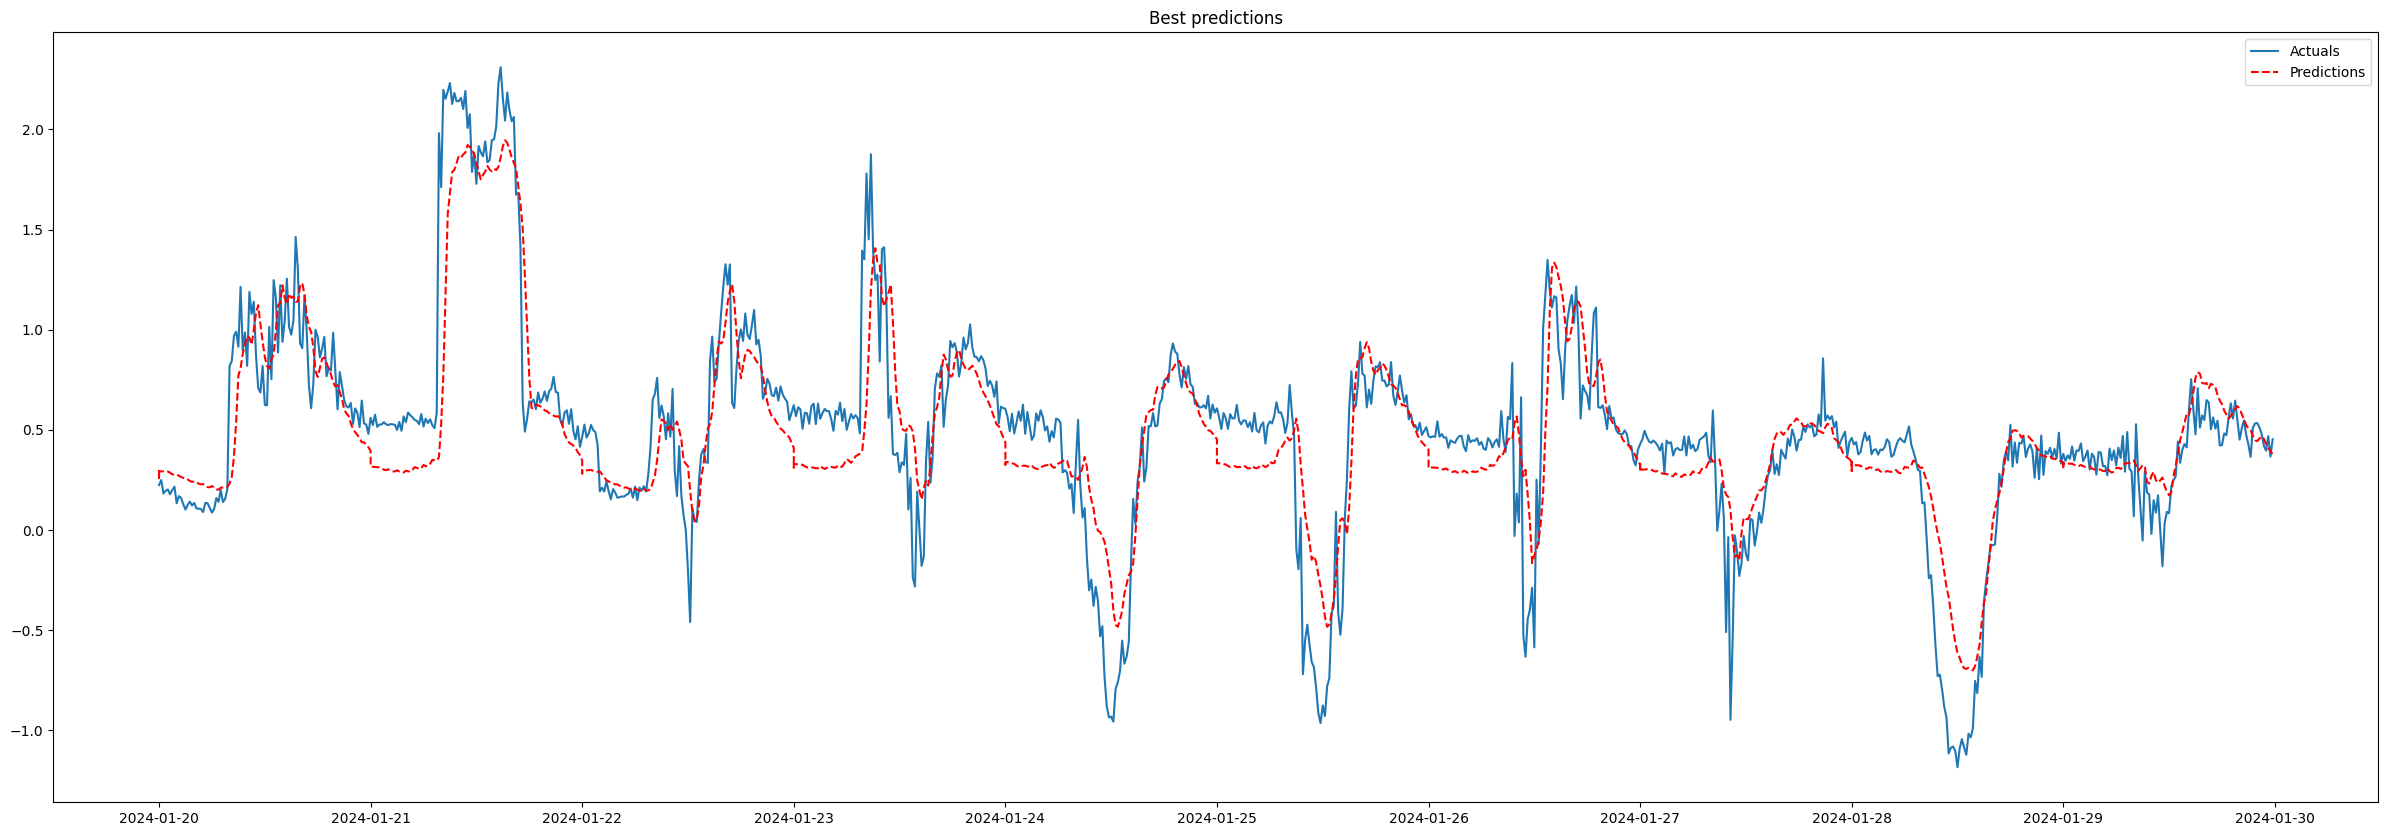

In [80]:
plt.figure(figsize=(30, 10))  # Set the size of the figure here
plt.plot(df['actual']['2024-01-20':'2024-01-29'], label='Actuals')
plt.plot(df['predictions']['2024-01-20':'2024-01-29'], label='Predictions',color='r',linestyle ='--')
plt.title("Best predictions")
plt.legend()
plt.show()

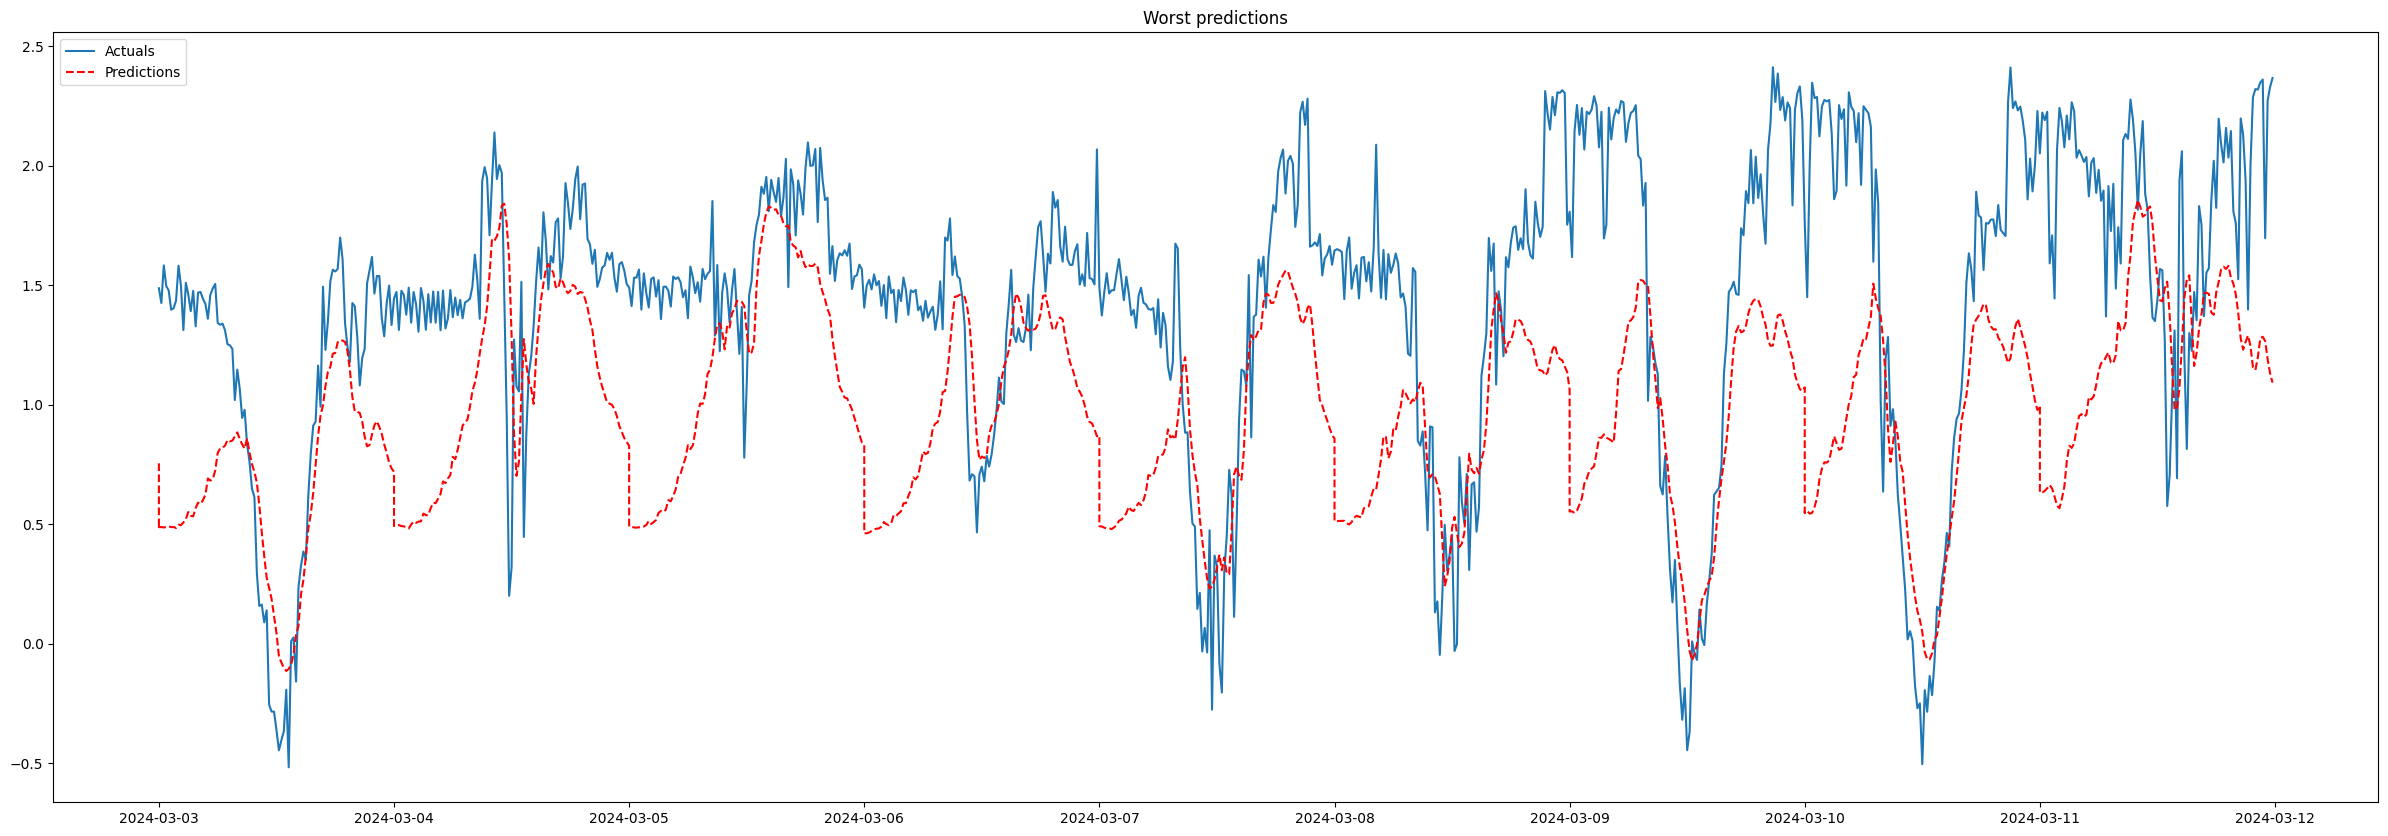

In [81]:
plt.figure(figsize=(30, 10))  # Set the size of the figure here
plt.plot(df['actual']['2024-03-03':'2024-03-11'], label='Actuals')
plt.plot(df['predictions']['2024-03-03':'2024-03-11'], label='Predictions',color='r',linestyle ='--')
plt.title("Worst predictions")
plt.legend()
plt.show()

XGBoost Model

In [79]:
#for cross validation
from sklearn.model_selection import TimeSeriesSplit

#import models for xgboost
import xgboost as xgb

In [82]:
train = df_train
test = df_val

features_xgb_reg = ['season','month','hour','hour_sin', 'hour_cos','year','week_cos','week_sin','National Holiday','apparent_temperature']
target = ['Power Usage']

tss = TimeSeriesSplit(n_splits=5, test_size=24*182*1, gap=24)
train = train.sort_index()

#lists to store data for each CV
scores = []
preds = []

#train the model on 5 seperate train, eval splits to find the best parameters and observe performance
for train_idx, eval_idx in tss.split(train):
    train_set = train.iloc[train_idx]
    eval_set = train.iloc[eval_idx]

    X_train = train_set[features_xgb_reg]
    y_train = train_set[target]
    X_eval = eval_set[features_xgb_reg]
    y_eval = eval_set[target]

    #define the model
    xgb_reg = xgb.XGBRegressor(n_estimators=1000, enable_categorical=True,
                                max_depth= 10, booster='gbtree',
                                early_stopping_rounds=10, base_score=0.5,
                                min_child_weight= 2, #avoid splitting when child is a few, smaller number leads to overfitting
                                gamma = 0.2, #Requires more gain before splitting, avoid overfitting
                                objective='reg:squarederror', learning_rate=1e-3, colsample_bytree= 0.4) #larger better test set MAPE, #'colsample_bytree','subsample'

#reg_lambda=1.5, reg_alpha=0.5
    #train the model
    history = xgb_reg.fit(X_train, y_train,
                eval_set = [(X_train, y_train), (X_eval, y_eval)],
                verbose=100) #early_stopping_rounds=10)

    y_pred = xgb_reg.predict(X_eval)
    preds.append(y_pred)
    score = mape(y_eval, y_pred)
    scores.append(score)

[0]	validation_0-rmse:0.74806	validation_1-rmse:0.65394
[100]	validation_0-rmse:0.72136	validation_1-rmse:0.64233
[200]	validation_0-rmse:0.69607	validation_1-rmse:0.63181
[300]	validation_0-rmse:0.67255	validation_1-rmse:0.62333
[400]	validation_0-rmse:0.65016	validation_1-rmse:0.61721
[500]	validation_0-rmse:0.63085	validation_1-rmse:0.61180
[600]	validation_0-rmse:0.61286	validation_1-rmse:0.60725
[700]	validation_0-rmse:0.59653	validation_1-rmse:0.60397
[800]	validation_0-rmse:0.58124	validation_1-rmse:0.60177
[900]	validation_0-rmse:0.56613	validation_1-rmse:0.59977
[969]	validation_0-rmse:0.55688	validation_1-rmse:0.59883
[0]	validation_0-rmse:0.74224	validation_1-rmse:0.70503
[100]	validation_0-rmse:0.71703	validation_1-rmse:0.68899
[200]	validation_0-rmse:0.69304	validation_1-rmse:0.67405
[300]	validation_0-rmse:0.67081	validation_1-rmse:0.66004
[400]	validation_0-rmse:0.64946	validation_1-rmse:0.64880
[500]	validation_0-rmse:0.63110	validation_1-rmse:0.63907
[600]	validation_0

In [83]:
print(f'Average of all the MAPE scores for Cross Validation: {np.mean(scores) : 0.4f}')
print(f'Fold Scores: {scores}')

Average of all the MAPE scores for Cross Validation:  60296215.0432
Fold Scores: [np.float64(301479821.2760217), np.float64(232.8029018848155), np.float64(293.3059902005439), np.float64(396.7267374582512), np.float64(331.10437352768577)]


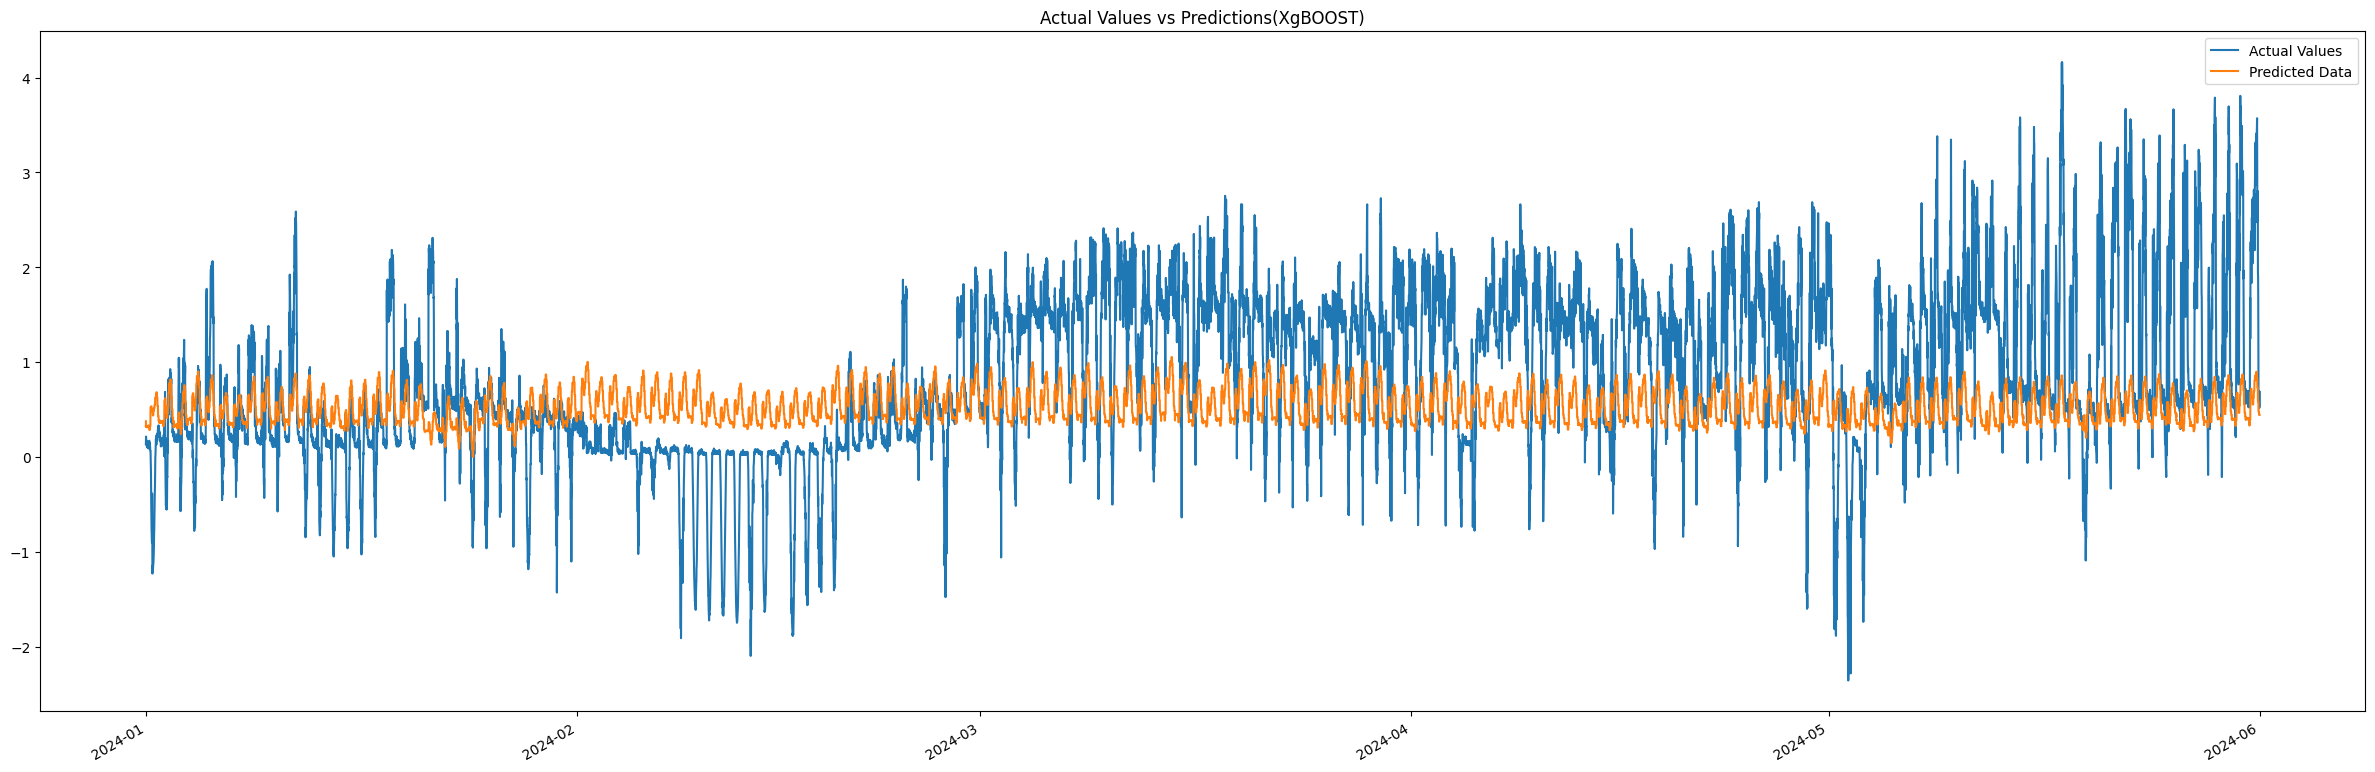

The root mean square error (RMSE) is: 0.90
The mean absolute error (MAE) is: 0.70
The mean absolute percentage error (sMAPE) is: 93.20%


In [89]:
X_test = test[features_xgb_reg]
y_test = test[target]

test['predictions'] = xgb_reg.predict(X_test)
#df = df.merge(test[['predictions']], how='left', left_index=True, right_index=True)

ax = y_test.plot(figsize=(30,10))
test['predictions'].plot(ax=ax)
plt.legend(['Actual Values', 'Predicted Data'])
plt.title("Actual Values vs Predictions(XgBOOST)")
plt.show()

# Evaluation
mse_score= mse(test['Power Usage'], test['predictions'])
rmse = np.sqrt(mse_score)
mae_value = mae(test['Power Usage'], test['predictions'])
mape_value = smape(test['Power Usage'], test['predictions'])

print(f"The root mean square error (RMSE) is: {rmse:.2f}")
print(f"The mean absolute error (MAE) is: {mae_value:.2f}")
print(f"The mean absolute percentage error (sMAPE) is: {mape_value:.2f}%")

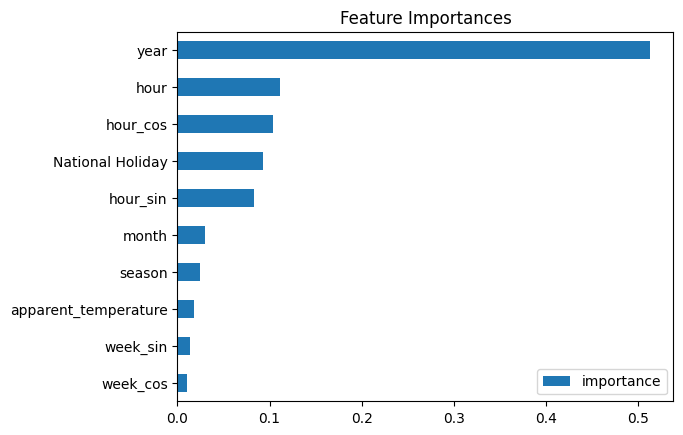

In [90]:
feat_imp = pd.DataFrame(data=xgb_reg.feature_importances_,
                        index = xgb_reg.feature_names_in_,
                        columns=['importance'])
feat_imp.sort_values('importance').plot(kind = 'barh')
plt.title("Feature Importances")
plt.show()

In [91]:
test['error'] = np.abs(test[target[0]] - test['predictions'])
test['date'] = test.index.date
print('Worst Predictions:')
display(test.groupby(['date'])['error'].mean().sort_values(ascending=False).head())
print('\nBest Predictions:')
display(test.groupby(['date'])['error'].mean().sort_values(ascending=True).head())

Worst Predictions:


,error
date,
2024-05-11,1.474253
2024-05-12,1.338684
2024-03-11,1.327115
2024-05-01,1.286110
2024-04-25,1.285156



Best Predictions:


,error
date,
2024-01-27,0.144145
2024-01-29,0.150599
2024-02-26,0.164447
2024-01-10,0.182766
2024-01-03,0.191443


<Figure size 2000x1000 with 0 Axes>

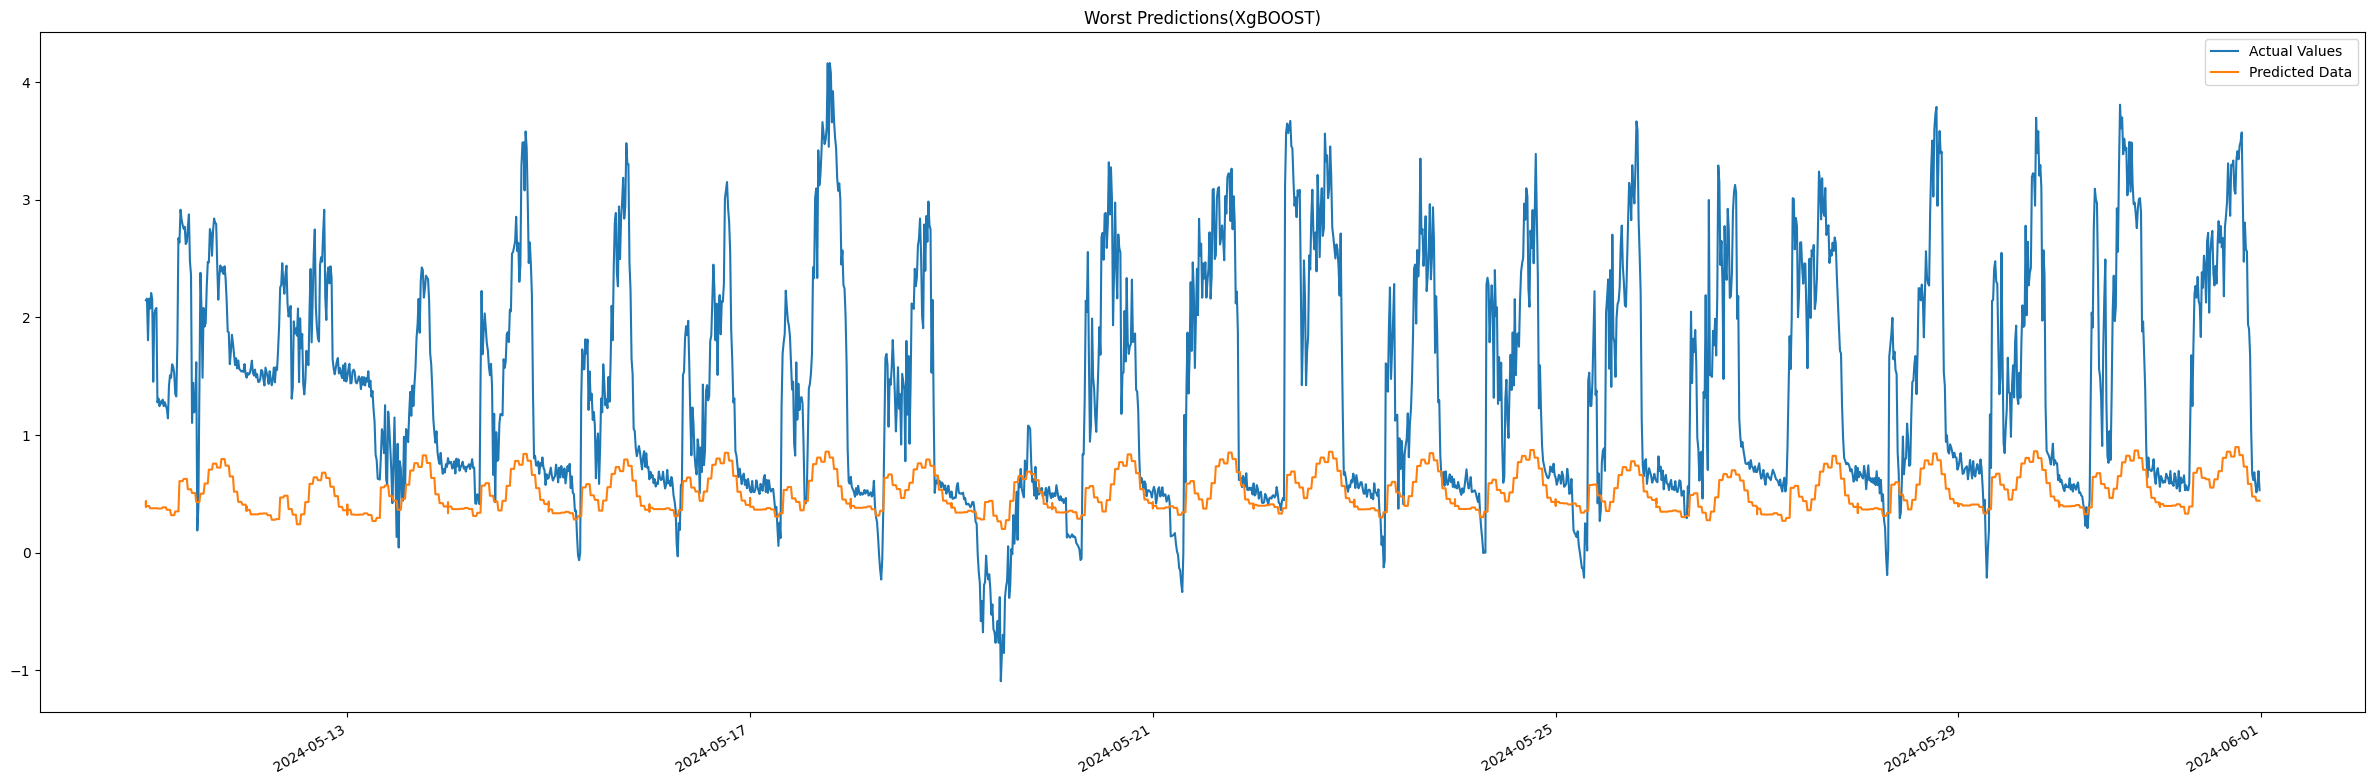

In [92]:
plt.figure(figsize=(20, 10))  # Set the size of the figure here

ax = y_test['2024-05-11':'2024-05-31'].plot(figsize=(30,10))
test['predictions']['2024-05-11':'2024-05-31'].plot(ax=ax)
plt.legend(['Actual Values', 'Predicted Data'])
plt.title("Worst Predictions(XgBOOST)")
plt.show()

<Figure size 2000x1000 with 0 Axes>

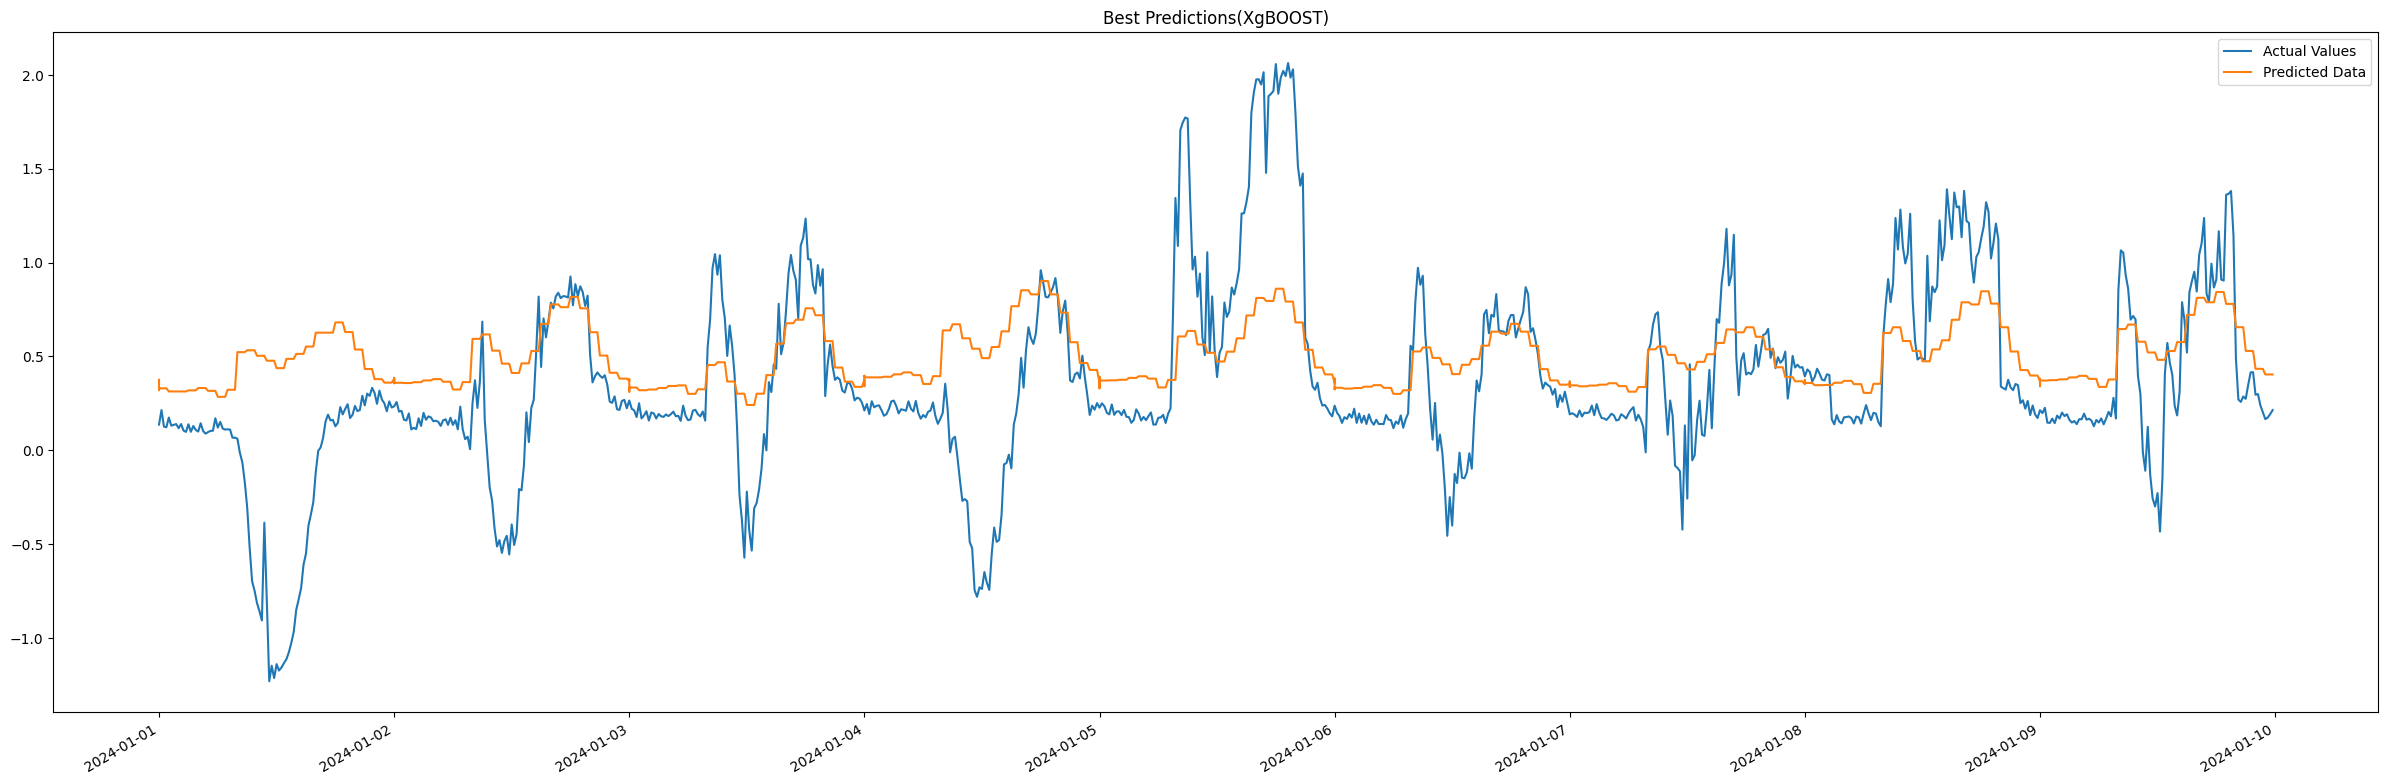

In [93]:
plt.figure(figsize=(20, 10))  # Set the size of the figure here

ax = y_test['2024-01-01':'2024-01-09'].plot(figsize=(30,10))
test['predictions']['2024-01-01':'2024-01-09'].plot(ax=ax)
plt.legend(['Actual Values', 'Predicted Data'])
plt.title("Best Predictions(XgBOOST)")
plt.show()